# Car Market Explorer Project

#### This notebook explores a dataset of car sales listings. The goal here is less about deep analysis and more about practicing real-world data engineering skills: cleaning messy data, preparing it for an app, and later deploying that app to the cloud.
#### Below, I clean the dataset step by step, documenting each decision along the way.

## 1. Import and overview

In [1]:
import pandas as pd
import plotly.express as px

- We need to make sure that everything is alright in this DataBase.

In [2]:
vehicles_df = pd.read_csv('../datasets/vehicles.csv')
print(vehicles_df.sample(5))
print()
vehicles_df.info()

       price  model_year                     model  condition  cylinders fuel  \
6372    4800      2010.0              nissan rogue       good        NaN  gas   
15099  24999      2016.0                ford f-150  excellent        8.0  gas   
23431  13950      2011.0  chevrolet silverado 1500       good        8.0  gas   
39283  25600         NaN  ford mustang gt coupe 2d       good        8.0  gas   
29799  10495      2008.0         toyota highlander  excellent        6.0  gas   

       odometer transmission   type paint_color  is_4wd date_posted  \
6372        NaN    automatic    SUV        grey     1.0  2018-08-08   
15099   60810.0    automatic  truck       black     1.0  2019-01-07   
23431       NaN    automatic  truck        blue     1.0  2018-12-02   
39283       NaN        other  coupe       black     NaN  2019-04-02   
29799  107387.0    automatic    SUV       black     NaN  2019-03-20   

       days_listed  
6372            84  
15099            2  
23431          157  
39

## 2. Data Cleaning

#### Our initial check showed some issues that need to be fixed:

1. Standardize the text columns "model", "condition", "fuel", "transmission", "type" and "paint_color" (remove extra spaces, lowercase);
2. Convert "date_posted" to datetime;
3. Check for fully duplicated rows and remove them;
4. Fix implicit duplicates in "model": names that refer to the same car but are written in different ways, such as "ford f150" and "ford f-150";
5. Treat as missing the "odometer" values under 100 miles, except for cars marked as "new", since this is unrealistic for a used car;
6. Handle missing values in "paint_color", "is_4wd", "model_year", "cylinders" and "odometer":
   * "paint_color": fill with "unknown";
   * "is_4wd": it only holds 1.0 or NaN, so NaN means the car is not 4WD. Fill with 0 and convert to boolean;
   * "model_year" and "odometer": fill with the median of similar vehicles instead of the overall median;
   * "cylinders": fill with the mode of the same model, since it holds fixed values;
7. Convert "model_year", "cylinders" and "odometer" to int64 only after their missing values are filled, since int64 does not accept NaN;
8. Remove outliers in "price", "odometer" and "model_year", using cutoffs chosen from cumulative curves;
9. Split the vehicle name into three columns: "car_name" (full name), "brand" and "model", to be used as filters in the app.

In [3]:
# Check for fully duplicated rows and remove them.
print(vehicles_df.duplicated().sum())
vehicles_df = vehicles_df.drop_duplicates().reset_index(drop=True)

0


In [4]:
# Standarize text columns and fill the missing values.
for col in ['model', 'condition', 'fuel', 'transmission', 'type', 'paint_color']:
    vehicles_df[col] = vehicles_df[col].str.strip().str.lower()

vehicles_df['date_posted'] = pd.to_datetime(vehicles_df['date_posted'],format='%Y-%m-%d')
vehicles_df['paint_color'] = vehicles_df['paint_color'].fillna('unknown')
vehicles_df['is_4wd'] = vehicles_df['is_4wd'].fillna(0).astype(bool)

In [5]:
sorted(vehicles_df['model'].unique())

['acura tl',
 'bmw x5',
 'buick enclave',
 'cadillac escalade',
 'chevrolet camaro',
 'chevrolet camaro lt coupe 2d',
 'chevrolet colorado',
 'chevrolet corvette',
 'chevrolet cruze',
 'chevrolet equinox',
 'chevrolet impala',
 'chevrolet malibu',
 'chevrolet silverado',
 'chevrolet silverado 1500',
 'chevrolet silverado 1500 crew',
 'chevrolet silverado 2500hd',
 'chevrolet silverado 3500hd',
 'chevrolet suburban',
 'chevrolet tahoe',
 'chevrolet trailblazer',
 'chevrolet traverse',
 'chrysler 200',
 'chrysler 300',
 'chrysler town & country',
 'dodge charger',
 'dodge dakota',
 'dodge grand caravan',
 'ford econoline',
 'ford edge',
 'ford escape',
 'ford expedition',
 'ford explorer',
 'ford f-150',
 'ford f-250',
 'ford f-250 sd',
 'ford f-250 super duty',
 'ford f-350 sd',
 'ford f150',
 'ford f150 supercrew cab xlt',
 'ford f250',
 'ford f250 super duty',
 'ford f350',
 'ford f350 super duty',
 'ford focus',
 'ford focus se',
 'ford fusion',
 'ford fusion se',
 'ford mustang',
 '

In [6]:
# Fix implicit duplicates in "model": vehicle names that refer to the same car but are written in different ways, such as "ford f150" and "ford f-150";
vehicles_df['model'] = vehicles_df['model'].replace({
    # Chevrolet
    'chevrolet silverado': 'chevrolet silverado 1500',
    'chevrolet silverado 1500 crew': 'chevrolet silverado 1500',
    'chevrolet camaro lt coupe 2d': 'chevrolet camaro',
    # Ford
    'ford f150': 'ford f-150',
    'ford f150 supercrew cab xlt': 'ford f-150',
    'ford f250': 'ford f-250',
    'ford f-250 sd': 'ford f-250',
    'ford f-250 super duty': 'ford f-250',
    'ford f250 super duty': 'ford f-250',
    'ford f350': 'ford f-350',
    'ford f-350 sd': 'ford f-350',
    'ford f350 super duty': 'ford f-350',
    'ford focus se': 'ford focus',
    'ford fusion se': 'ford fusion',
    'ford mustang gt coupe 2d': 'ford mustang',
    # GMC
    'gmc sierra': 'gmc sierra 1500',
    # Honda, Toyota, Nissan
    'honda civic lx': 'honda civic',
    'toyota camry le': 'toyota camry',
    'nissan frontier crew cab sv': 'nissan frontier',
    # Jeep
    'jeep grand cherokee laredo': 'jeep grand cherokee',
    'jeep wrangler unlimited': 'jeep wrangler',
    # Mercedes (typo "benze")
    'mercedes-benz benze sprinter 2500': 'mercedes-benz sprinter 2500'
})

In [7]:
#Checking and fixing cars with unrealistic odometer values (under 500 miles, excluding new cars)
vehicles_df['odometer'] = vehicles_df['odometer'].mask(
(vehicles_df['odometer'] < 500) & (vehicles_df['condition'] != 'new'))

In [8]:
# Fill the missing values with the median.
vehicles_df['model_year'] = vehicles_df['model_year'].fillna(
    vehicles_df.groupby('model')['model_year'].transform('median'))

def get_mode(x):
    return x.mode()[0]
vehicles_df['cylinders'] = vehicles_df['cylinders'].fillna(
    vehicles_df.groupby('model')['cylinders'].transform(get_mode))
# For cylinders we are fullfilling with the 'mode' instead of 'median'.

vehicles_df['odometer'] = (vehicles_df['odometer']
    .fillna(vehicles_df.groupby(['model', 'condition', 'model_year'])['odometer'].transform('median'))
    .fillna(vehicles_df.groupby('model')['odometer'].transform('median'))
    .fillna(vehicles_df['odometer'].median()))

# To verify if our treatment got right.
vehicles_df.isna().sum()

price           0
model_year      0
model           0
condition       0
cylinders       0
fuel            0
odometer        0
transmission    0
type            0
paint_color     0
is_4wd          0
date_posted     0
days_listed     0
dtype: int64

In [9]:
# Convert 'model_year' Dtype to the right one.
vehicles_df['model_year'] = vehicles_df['model_year'].astype('int')
vehicles_df['cylinders'] = vehicles_df['cylinders'].astype('int')
vehicles_df['odometer'] = vehicles_df['odometer'].astype('int')

In [10]:
# Now we check the outliers on Data Frame:
print(vehicles_df.describe())
print()
print(len(vehicles_df))

               price    model_year     cylinders       odometer  \
count   51525.000000  51525.000000  51525.000000   51525.000000   
mean    12132.464920   2009.803901      6.124716  117457.003765   
min         1.000000   1908.000000      3.000000       5.000000   
25%      5000.000000   2007.000000      4.000000   74923.000000   
50%      9000.000000   2011.000000      6.000000  115500.000000   
75%     16839.000000   2014.000000      8.000000  154000.000000   
max    375000.000000   2019.000000     12.000000  990000.000000   
std     10040.803015      6.092261      1.659000   61444.407288   

                      date_posted  days_listed  
count                       51525  51525.00000  
mean   2018-10-25 01:57:46.270742     39.55476  
min           2018-05-01 00:00:00      0.00000  
25%           2018-07-29 00:00:00     19.00000  
50%           2018-10-25 00:00:00     33.00000  
75%           2019-01-21 00:00:00     53.00000  
max           2019-04-19 00:00:00    271.00000  
std 

#### Our suspects were right, we have outliers in "price", "odometer" and "model_year", now we need to correct it.

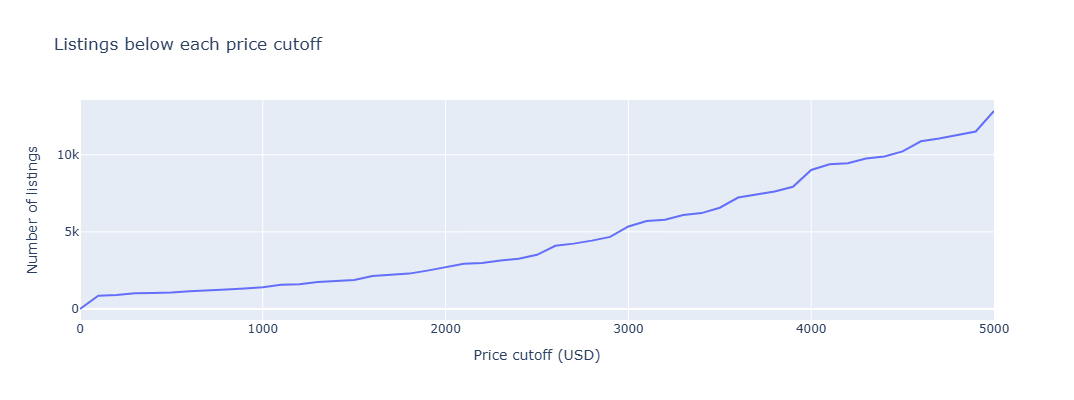

In [11]:
# Count how many listings fall below each candidate price cutoff.

cutoffs = range(0, 5001, 100)

px.line(
    x=cutoffs,
    y=[(vehicles_df['price'] < c).sum() for c in cutoffs],
    title='Listings below each price cutoff',
    labels={'x': 'Price cutoff (USD)', 'y': 'Number of listings'},
    width=700,
    height=400
)

In [12]:
(vehicles_df['price'] < 100).sum()

np.int64(863)

#### The graph shows that the values stabilized after the limit reached 100 USD, so that will be our cutoff. Removing listings below this value drops only 863 rows (about 1.7% of the data).

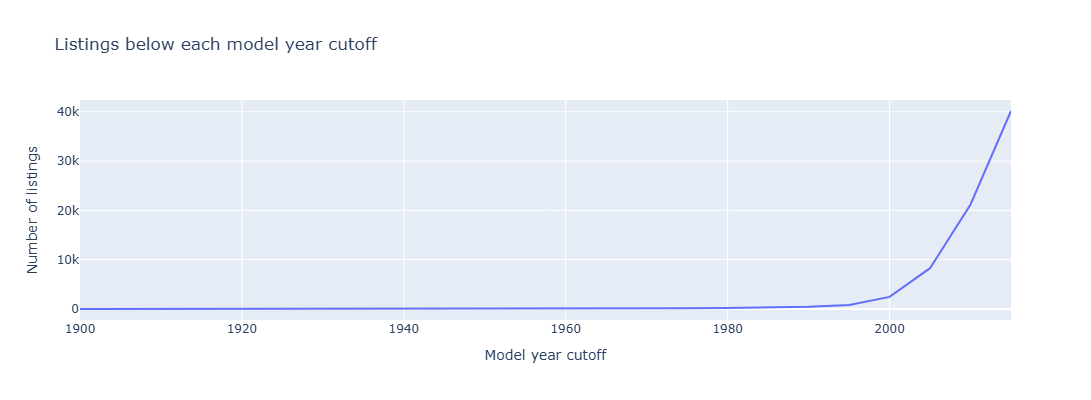

In [13]:
# Count how many listings have a model year below each candidate cutoff.
cutoffs = range(1900, 2018, 5)

px.line(
    x=cutoffs,
    y=[(vehicles_df['model_year'] < c).sum() for c in cutoffs],
    title='Listings below each model year cutoff',
    labels={'x': 'Model year cutoff', 'y': 'Number of listings'},
    width=700,
    height=400
)

In [14]:
(vehicles_df['model_year'] < 1975).sum()

np.int64(134)

#### The graph shows that the values stabilized after the limit reached 100 USD, so that will be our cutoff. Removing listings below this value drops only 863 rows (about 1.7% of the data).

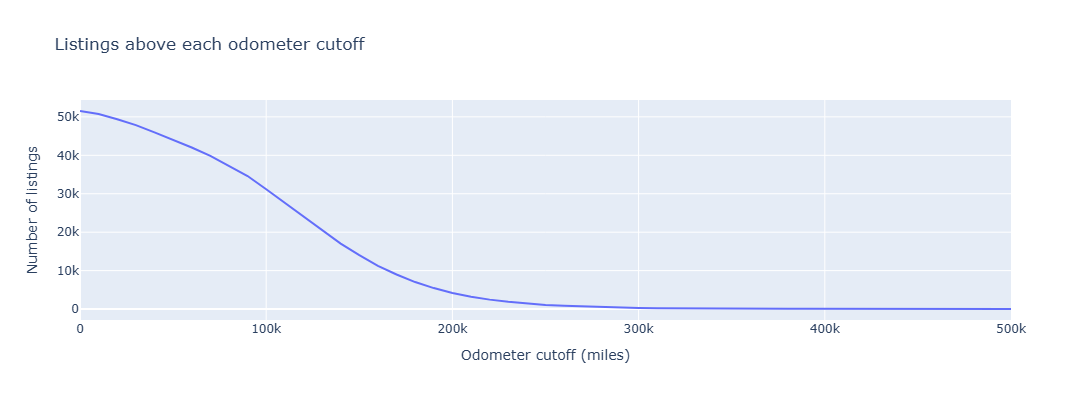

In [15]:
# Count how many listings have an odometer above each candidate cutoff.
cutoffs = range(0, 500001, 10000)

px.line(
    x=cutoffs,
    y=[(vehicles_df['odometer'] > c).sum() for c in cutoffs],
    title='Listings above each odometer cutoff',
    labels={'x': 'Odometer cutoff (miles)', 'y': 'Number of listings'},
    width=700,
    height=400
)

In [16]:
print((vehicles_df['odometer'] > 300000).sum())

290


#### The graph shows that the curve flattens out at around 300k miles, so that will be our cutoff. Removing listings above this value drops only 287 rows (about 0.56% of the data).

In [17]:
# Remove the outliers.

MIN_PRICE = 100
MIN_YEAR = 1975
MAX_ODOMETER = 300000

vehicles_df = vehicles_df[
    (vehicles_df['price'] >= MIN_PRICE) &
    (vehicles_df['model_year'] >= MIN_YEAR) &
    (vehicles_df['odometer'] <= MAX_ODOMETER)
].reset_index(drop=True)

In [18]:
# Create columns that will help us in our Dashboard.
vehicles_df = vehicles_df.rename(columns={'model': 'car_name'})
vehicles_df['brand'] = vehicles_df['car_name'].str.split().str[0]
vehicles_df['model'] = vehicles_df['car_name'].str.split(n=1).str[1]
vehicles_df['brand'].value_counts()

brand
ford             12382
chevrolet        10323
toyota            5301
honda             3409
jeep              3185
ram               3150
nissan            3139
gmc               2325
subaru            1269
hyundai           1170
dodge             1170
volkswagen         862
chrysler           834
kia                585
cadillac           321
buick              271
bmw                267
acura              236
mercedes-benz       41
Name: count, dtype: int64

In [19]:
print(vehicles_df.sample(5))
vehicles_df.info()

       price  model_year                  car_name  condition  cylinders fuel  \
49629   9995        2007              jeep liberty  excellent          6  gas   
29284  19990        2006         gmc sierra 2500hd       good          8  gas   
35942   2000        1999                honda cr-v       good          4  gas   
31273   4990        1998                 gmc yukon       good          8  gas   
25377   5800        1999  chevrolet silverado 1500  excellent          8  gas   

       odometer transmission    type paint_color  is_4wd date_posted  \
49629     59277    automatic     suv       black    True  2018-07-11   
29284    113648    automatic   truck      custom    True  2018-09-10   
35942    241000    automatic     suv       black   False  2019-02-08   
31273    149865    automatic     suv      silver    True  2018-10-22   
25377    211725    automatic  pickup        blue    True  2019-03-15   

       days_listed      brand           model  
49629           38       jeep   

### Conclusion

The dataset is now clean and ready to power the app. Missing values were filled with the median of similar vehicles (or the most common value, in the case of "cylinders"), and the remaining columns were handled according to what they represent: a missing color became "unknown", and a missing "is_4wd" meant the car simply isn't 4WD. No duplicated rows were found, and all text columns were standardized. I also fixed implicit duplicates in the vehicle names, so each car is counted only once in the rankings.

I also found some used cars listed with an odometer under 100 miles, which is unrealistic for anything other than a brand new car. I treated these as missing values, except for cars marked as "new", and filled them using the median "odometer" of similar vehicles.

To keep the analysis reliable, I removed outliers using cutoffs chosen from cumulative curves rather than guesswork: listings priced below 100 USD (863 rows), with more than 300k miles (287 rows) or older than 1975 (134 rows). Together, these cuts leave a final dataset of 50,243 rows, down from 51,525.

Finally, I split the vehicle name into "car_name", "brand" and "model". This will make it possible to filter by brand and to rank the most listed cars in the dashboard.

## 3. Data Test 

#### With the data cleaned, it is time to see what it actually looks like. In this section, I build the charts that will later become the dashboard, testing each one here first so I know they work before moving them into the app. Each chart answers a simple question about the market:
1. how prices are distributed;
2. how mileage affects price;
3. how prices change with the condition of the vehicle;
4. which brands dominate the listings;
5. which specific cars are the most listed, with a little podium for the top three;
6. how listings split by transmission type;
7. how many listings are 4WD.

### 3.1. Car Price Histogram

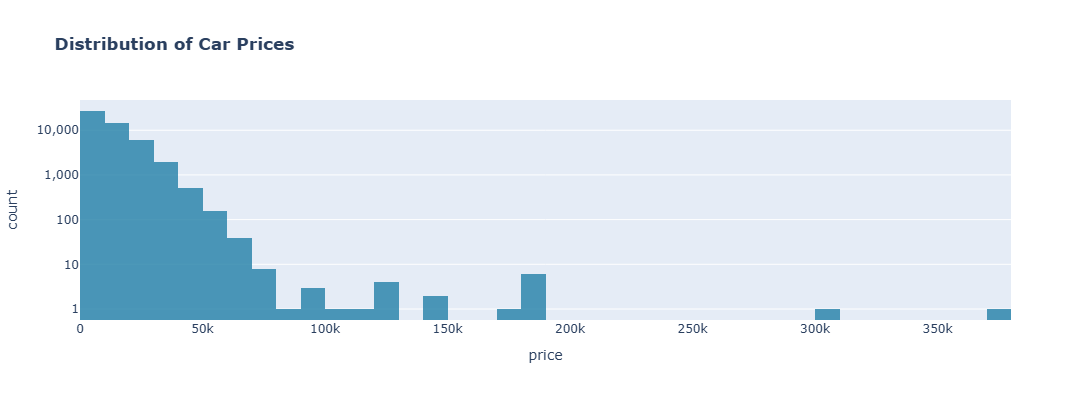

In [20]:
px.histogram(vehicles_df,
             x='price', 
             nbins=60, 
             title='<b>Distribution of Car Prices</b>',
             color_discrete_sequence=['#2E86AB'], 
             opacity=0.85,
             log_y=True, 
             width=700, 
             height=400).update_yaxes(dtick=1, tickformat=',')

#### This histogram shows how listing prices are distributed. Most listings are priced below 30k USD, and a few isolated ones reach 300k and 350k USD, which may be rare cars or data entry errors. The y-axis uses a logarithmic scale, so each step represents ten times more listings.

### 3.2. Price x Odometer Dispersion

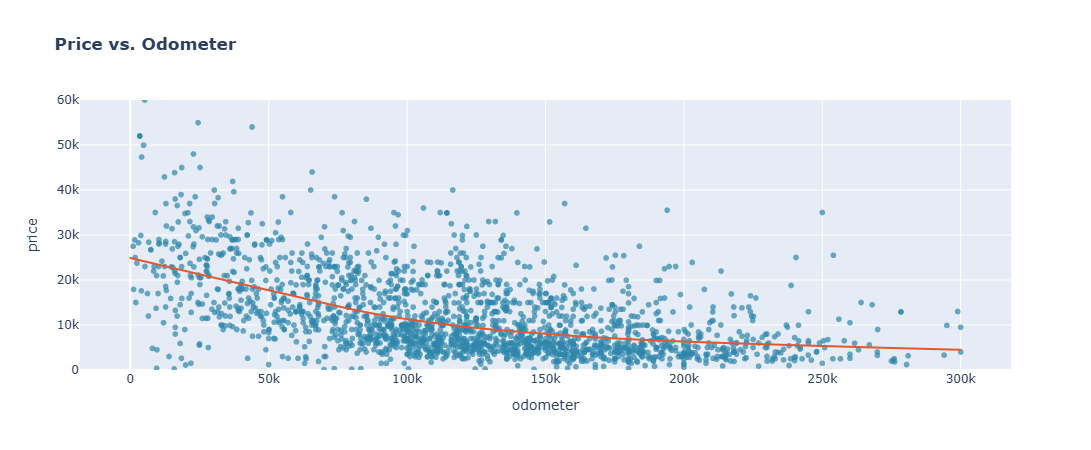

In [21]:
px.scatter(vehicles_df.sample(2000, random_state=32),
           x='odometer', 
           y='price',
           opacity=0.7, 
           trendline='lowess', 
           trendline_color_override='#E4572E',
           color_discrete_sequence=['#2E86AB'], 
           range_y=[0, 60000],
           title='<b>Price vs. Odometer</b>', 
           width=700, 
           height=450)

#### This scatter plot compares mileage and price for a random sample of 2,000 listings. Price falls steadily as mileage rises, dropping fastest in the first 100k miles. The y-axis stops at 60k USD to keep the chart readable.

### 3.3. Price by Condition Box Plot

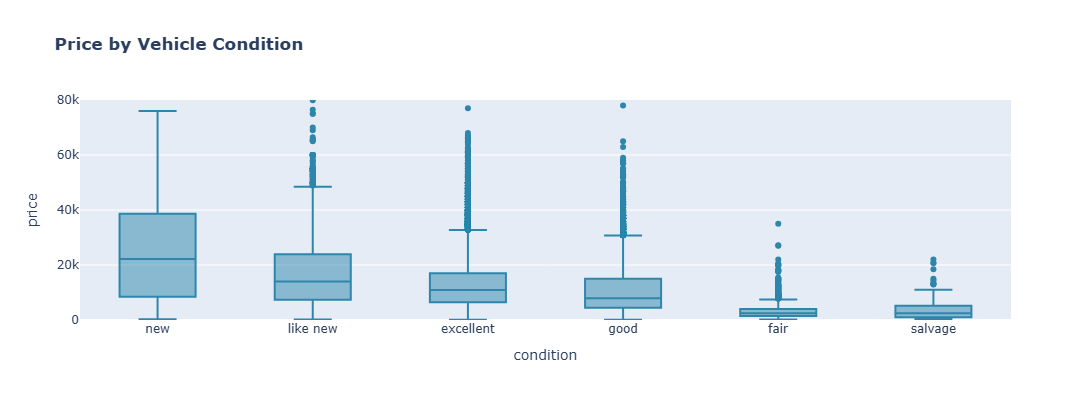

In [22]:
px.box(vehicles_df,
       x='condition',
       y='price',
       category_orders={'condition': ['new', 'like new', 'excellent', 'good', 'fair', 'salvage']},
       color_discrete_sequence=['#2E86AB'],
       range_y=[0, 80000],
       title='<b>Price by Vehicle Condition</b>',
       width=700,
       height=400)

#### This box plot shows how prices vary within each vehicle condition.
* The median price falls from "new" to "fair", and "salvage" is close to "fair".
* The dots above the boxes are listings priced well above the typical for their condition, since car prices are skewed toward expensive models.
* The y-axis stops at 80k USD to keep the chart readable.

### 3.4. Top 10 Brands Bar Chart

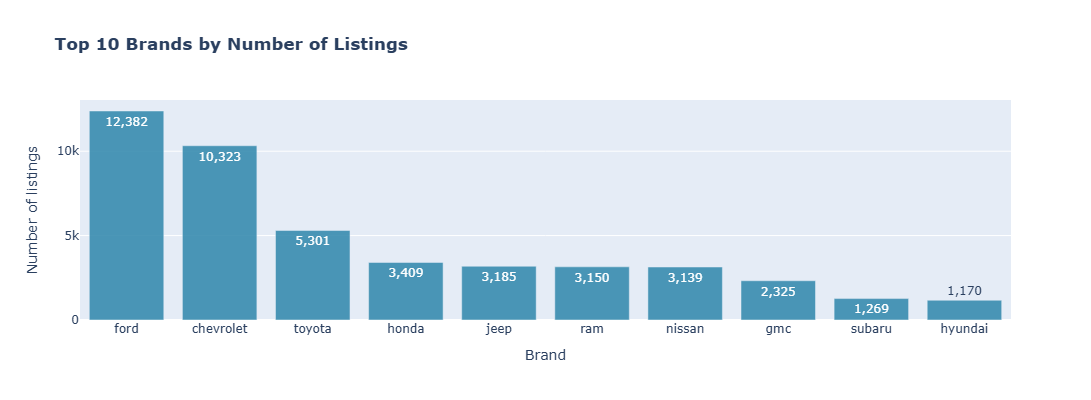

In [23]:
px.bar(vehicles_df['brand'].value_counts().head(10).reset_index(),
       x='brand',
       y='count',
       text_auto=',d',
       color_discrete_sequence=['#2E86AB'],
       opacity=0.85,
       title='<b>Top 10 Brands by Number of Listings</b>',
       labels={'brand': 'Brand', 'count': 'Number of listings'},
       width=700,
       height=400).update_traces(textangle=0)

#### This chart ranks the ten brands with the most listings.
* "Ford" and "Chevrolet" lead by a wide margin, with more than 10k listings each, about 45% of the dataset together.
* "Toyota" comes next with about 5k, and the four brands after it ("Honda", "Jeep", "Ram" and "Nissan") sit around 3k each.

### 3.5. Top 5 Most Listed Cars

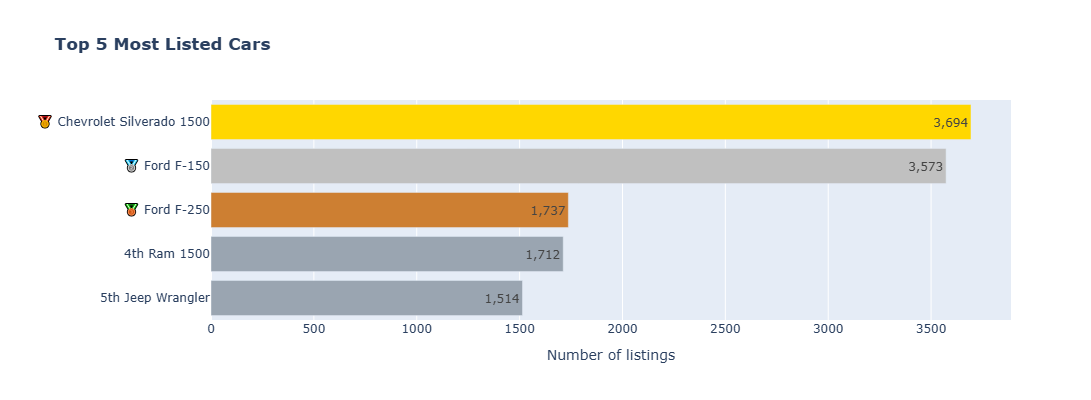

In [24]:
px.bar(vehicles_df['car_name'].value_counts().head(5).reset_index()
           .assign(label=lambda d: pd.Series(['🥇', '🥈', '🥉', '4th', '5th']) + ' ' + d['car_name'].str.title()),
       x='count',
       y='label',
       color='label',
       orientation='h',
       text_auto=',d',
       color_discrete_sequence=['#FFD700', '#C0C0C0', '#CD7F32', '#9AA5B1', '#9AA5B1'],
       title='<b>Top 5 Most Listed Cars</b>',
       labels={'count': 'Number of listings', 'label': ''},
       width=800,
       height=400).update_layout(showlegend=False,
                                 hovermode=False,
                                 yaxis={'categoryorder': 'total ascending', 'automargin': True}).update_traces(textangle=0)

#### This chart shows the five most listed cars, with medals for the podium.
* "Chevrolet Silverado 1500" takes the gold medal with 3,694 listings, followed closely by "Ford F-150" (3,573) and then "Ford F-250" (1,739).
* "Ram 1500" (1,712) and "Jeep Wrangler" (1,514) close the top 5.
* Pickup trucks dominate the ranking, taking four of the five spots.

### 3.6. Listings by Transmission Type

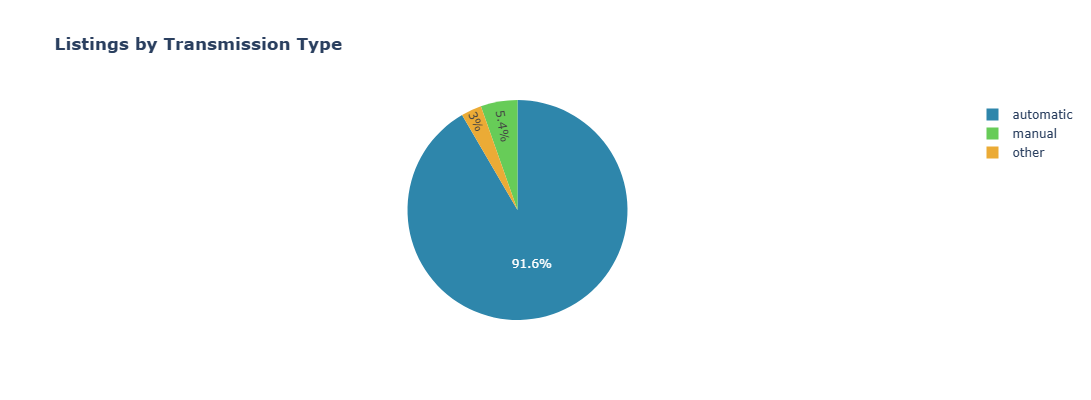

In [25]:
px.pie(vehicles_df,
       names='transmission',
       color_discrete_sequence=['#2E86AB', '#67CC58','#EBAB36'],
       title='<b>Listings by Transmission Type</b>',
       width=700,
       height=400)

#### This pie chart shows the share of each transmission type.
* "Automatic" dominates the market, with 91.6% of the listings.
* "Manual" represents only 5.41% and "other" 3%.

### 3.7. 4WD Listings

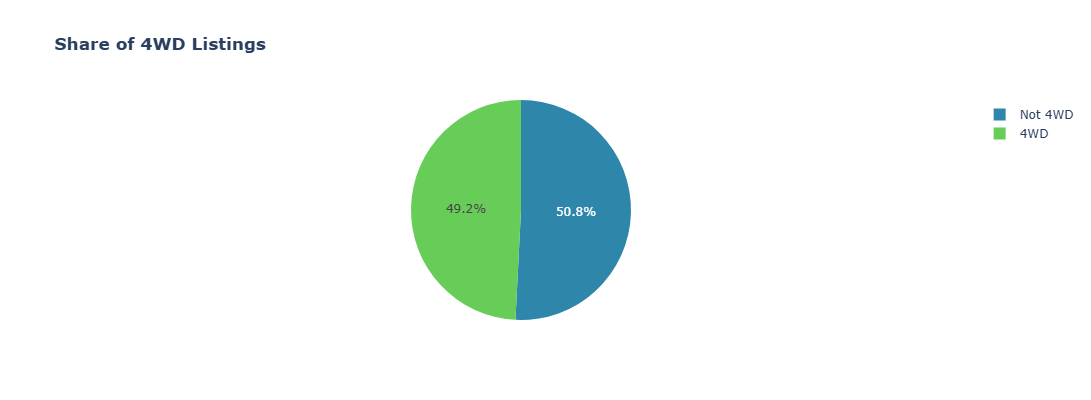

In [26]:
px.pie(names=vehicles_df['is_4wd'].map({True: '4WD', False: 'Not 4WD'}),
       color_discrete_sequence=['#2E86AB', '#67CC58'],
       title='<b>Share of 4WD Listings</b>',
       width=700,
       height=400)

#### This pie chart shows how many listings are 4WD.
* "4WD" represents 49.2% of the listings and "Not 4WD" the other 50.8%.
* In the original data, only 4WD cars were marked, so "Not 4WD" may also include listings with no information.

## 4. Final Conclusion

#### Looking at the charts together, a few patterns stand out. "Ford" is the brand with the most listings and has two models in the top three ("F-150" and "F-250"), but the single most listed car is the "Chevrolet Silverado 1500" (3,694), just ahead of the "Ford F-150" (3,573). Brand popularity and model popularity do not always move together.

#### Prices follow the usual used car pattern: most listings are below 30k USD, and a few expensive outliers stretch the distribution to the right. Price also falls steadily as the odometer rises, fastest in the first 100k miles, and the median price drops from "new" to "fair".
### Price behaves as expected from a used car market: most listings are affordable, concentrated below 30k USD, and a small number of expensive outliers pull the distribution to the right. Mileage reinforces this pattern, since price drops sharply as the odometer rises, especially in the first 100k miles, which matches what buyers typically look for in a used car.

In [27]:
# Export clean DataFrame
vehicles_df.to_csv('../datasets/vehicles_clean.csv', index=False)